# 6. Optimización computacional

Los experimentos de esta sección se ejecutaron con la máquina libre (después de la validación anidada), con un hilo por proceso salvo en el análisis de paralelización, y cada tiempo es el promedio de dos o tres repeticiones. Los modelos se miden sobre la matriz ya preprocesada (49 columnas densas), para aislar el costo del algoritmo. La máquina tiene 12 núcleos lógicos y no tiene GPU NVIDIA.

## 6.1 Complejidad algorítmica teórica

La tabla resume la complejidad de entrenamiento e inferencia de cada modelo en función de n (observaciones), p (características), B (árboles), k (vecinos), m (componentes de Nyström) y n_sv (vectores de soporte). Las secciones siguientes la contrastan con el tiempo medido y con el **exponente empírico**, la pendiente de log(tiempo) frente a log(n): un exponente cercano a 1 es lineal y cercano a 2, cuadrático.

In [53]:
RC = RES / "computacional"
cp = {f.stem: pd.read_parquet(f) for f in RC.glob("*.parquet")}
with open(RC / "perfil.pkl", "rb") as f:
    perfil = pickle.load(f)
tabla(comp.COMPLEJIDAD, indice=False)
exportar("comp_complejidad", comp.COMPLEJIDAD)
for k_, v_ in cp.items():
    if k_ != "perfil_tabla":
        exportar(f"comp_{k_}", v_)
exportar("comp_perfil", {"total_s": perfil["total_s"], "memoria_pico_mb": perfil["memoria_pico_mb"]})


def exponentes(df, x="n", y="Ajuste (s)", grupo="Método"):
    return df.groupby(grupo).apply(lambda g: comp.exponente(g[x], g[y]), include_groups=False).rename("Exponente empírico")


def grafico_escalamiento(ax, df, y, titulo, grupo="Método"):
    for i, (m_, g) in enumerate(df.groupby(grupo, sort=False)):
        ax.loglog(g["n"], g[y], marker="o", color=CAT[i], label=m_)
    ax.set(title=titulo, xlabel="n (escala log)", ylabel=f"{y} (escala log)")
    ax.legend(fontsize=7)

Modelo,Entrenamiento,Inferencia,Implementación
KNN (búsqueda exhaustiva),O(1) (solo almacena),O(n · p) por consulta,brute
KNN (KD-Tree / Ball Tree),O(p · n log n),O(log n) en baja dimensión; tiende a O(n · p) si p es alto,kd_tree / ball_tree
KNN aproximado (FAISS HNSW),O(n log n · M),"≈ O(log n) por consulta, con pérdida de exactitud",IndexHNSWFlat
Naive Bayes gaussiano,O(n · p),O(p · c) por consulta,fit / partial_fit
Regresión logística (SAGA),O(n · p) por época,O(p) por consulta,solver saga
Ridge (Cholesky),O(n · p² + p³),O(p),cholesky
Ridge / Lasso (SAGA o SGD),O(n · p) por época,O(p),saga / SGD
Lasso (descenso por coordenadas),O(n · p) por pasada,O(p),cd
Árbol de decisión,O(p · n log n),O(profundidad),CART
Random Forest,O(B · p' · n log n),O(B · profundidad),"B árboles, p' variables por división"


## 6.2 KNN: búsqueda exhaustiva, KD-Tree, Ball Tree y vecinos aproximados con FAISS

Se buscan los 40 vecinos de las 8 236 observaciones de prueba entre las 32 940 de entrenamiento. Además del tiempo, se mide el *recall*@40 de cada método frente a la búsqueda exacta y el AUC-PR del clasificador que resulta de la proporción de vecinos positivos, que es el costo en exactitud de la aproximación.

Método,Búsqueda,Construcción (s),Consulta prueba (s),ms por consulta,Recall@k vs exacta,AUC-PR (prueba)
sklearn brute,exacta,"0,0025","3,0447","0,3697","1,0000","0,5060"
sklearn kd_tree,exacta,"0,3809","7,6172","0,9249","0,9953","0,5055"
sklearn ball_tree,exacta,"0,2270","20,4339","2,4810","0,9957","0,5056"
FAISS IndexFlatL2,exacta,"0,0039","1,9328","0,2347","0,9945","0,5057"
FAISS IndexHNSWFlat (M = 32),aproximada,"1,8577","0,2637","0,0320","0,8901","0,4850"
"FAISS IndexIVFFlat (100 listas, nprobe = 8)",aproximada,"0,2018","0,6198","0,0753","0,9911","0,5058"


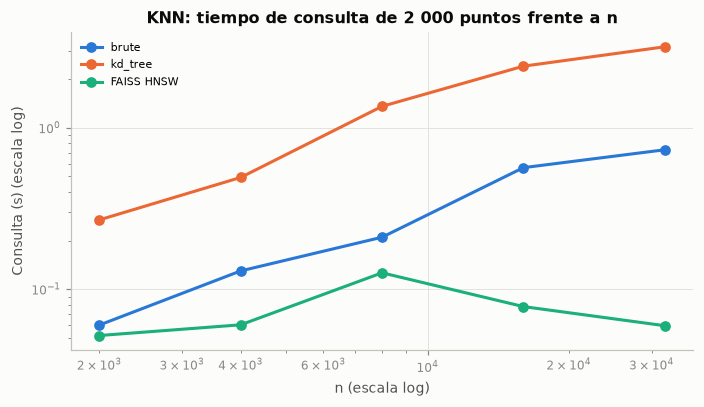

,Exponente empírico
Método,
FAISS HNSW,"0,08"
brute,"0,93"
kd_tree,"0,94"


**Interpretación.** La búsqueda exhaustiva tarda 3,04 s en consultar la prueba, el KD-Tree 7,62 s y FAISS HNSW 0,26 s, con un *recall*@40 de 0,890 frente a la búsqueda exacta y un AUC-PR de 0,4850 (exacta: 0,5060). El exponente empírico de la consulta es 0,08 (FAISS HNSW), 0,93 (brute) y 0,94 (kd_tree).

Esto significa que con 49 dimensiones, la mayoría binarias, los árboles de partición espacial pierden su ventaja teórica de O(log n): la maldición de la dimensionalidad obliga a visitar muchas hojas y el KD-Tree se acerca al costo exhaustivo, que además aprovecha BLAS. El grafo HNSW de FAISS sí escala de forma sublineal porque sacrifica exactitud, y en este problema esa pérdida casi no cambia la métrica.

Por lo anterior, conviene usar la búsqueda exhaustiva vectorizada en la validación anidada (lo que se hizo, con `algorithm='brute'`) y reservar FAISS para escenarios de inferencia masiva, donde el ahorro por consulta compensa la construcción del índice y la pérdida de exactitud es aceptable.

In [54]:
kb = cp["knn_busqueda"]
tabla(kb, dec=4, indice=False)
ke = cp["knn_escalamiento"]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
grafico_escalamiento(ax, ke, "Consulta (s)", "KNN: tiempo de consulta de 2 000 puntos frente a n")
plt.tight_layout()
plt.show()
exp_knn = exponentes(ke, y="Consulta (s)")
tabla(exp_knn.to_frame(), dec=2)

bru = kb[kb["Método"] == "sklearn brute"].iloc[0]
kd = kb[kb["Método"] == "sklearn kd_tree"].iloc[0]
hn = kb[kb["Método"].str.contains("HNSW")].iloc[0]
interpretar(
    f"La búsqueda exhaustiva tarda {num(bru['Consulta prueba (s)'], 2)} s en consultar la prueba, el KD-Tree "
    f"{num(kd['Consulta prueba (s)'], 2)} s y FAISS HNSW {num(hn['Consulta prueba (s)'], 2)} s, con un *recall*@40 de "
    f"{num(hn['Recall@k vs exacta'], 3)} frente a la búsqueda exacta y un AUC-PR de {num(hn['AUC-PR (prueba)'], 4)} "
    f"(exacta: {num(bru['AUC-PR (prueba)'], 4)}). El exponente empírico de la consulta es "
    f"{enumerar([num(v, 2) + ' (' + k + ')' for k, v in exp_knn.items()], codigo=False)}.",
    conectar("Esto significa que", "Con 49 dimensiones, la mayoría binarias, los árboles de partición espacial pierden su "
             "ventaja teórica de O(log n): la maldición de la dimensionalidad obliga a visitar muchas hojas y el "
             "KD-Tree se acerca al costo exhaustivo, que además aprovecha BLAS. El grafo HNSW de FAISS sí escala de forma "
             "sublineal porque sacrifica exactitud, y en este problema esa pérdida casi no cambia la métrica."
             if kd["Consulta prueba (s)"] > 0.5 * bru["Consulta prueba (s)"] else
             "Incluso con 49 dimensiones el KD-Tree mantiene una ventaja sobre la búsqueda exhaustiva, porque muchas "
             "columnas binarias reducen la dimensión efectiva; FAISS HNSW la amplía a costa de una pérdida mínima de "
             "exactitud."),
    conectar("Por lo anterior, conviene", "Usar la búsqueda exhaustiva vectorizada en la validación anidada (lo que se "
             "hizo, con `algorithm='brute'`) y reservar FAISS para escenarios de inferencia masiva, donde el ahorro por "
             "consulta compensa la construcción del índice y la pérdida de exactitud es aceptable."))

## 6.3 Ridge, Lasso y regresión logística: solucionadores

La guía sugiere SAGA, cuyo costo por época es lineal en n y p y que admite matrices dispersas. Se compara con los solucionadores directos (Cholesky, SVD), con el descenso por coordenadas del Lasso y con SGD, midiendo el tiempo de ajuste y la métrica en prueba.

Modelo,Solucionador,Ajuste (s),Desv. (s),Métrica,Valor
Ridge,cholesky,"0,0243","0,0069",RMSE,"1,0972"
Ridge,svd,"0,1951","0,0145",RMSE,"1,0973"
Ridge,sag,"7,2652","0,6553",RMSE,"1,0959"
Ridge,saga,"14,0636","0,5573",RMSE,"1,0866"
Lasso,descenso por coordenadas,"0,1041","0,0085",RMSE,"1,0173"
Lasso,SGD (L1),"0,1967","0,0079",RMSE,"1,4410"
Logística L2,lbfgs,"0,0946","0,0067",AUC-PR,"0,5484"
Logística L2,saga,"1,7024","0,1525",AUC-PR,"0,5497"
Logística L1,saga,"0,8945","0,0169",AUC-PR,"0,5406"
Logística L1,liblinear,"0,2062","0,0313",AUC-PR,"0,5719"


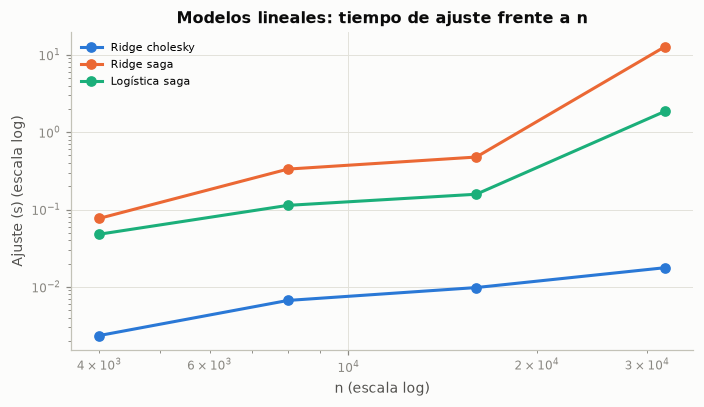

,Exponente empírico
Método,
Logística saga,"1,63"
Ridge cholesky,"0,93"
Ridge saga,"2,26"


**Interpretación.** Ridge con Cholesky se ajusta en 0,024 s y con SAGA en 14,064 s, con un RMSE de 1,0972 y 1,0866. Los exponentes empíricos son 1,63 (Logística saga), 0,93 (Ridge cholesky) y 2,26 (Ridge saga).

Hay que tener en cuenta que con p = 49, el término p³ de Cholesky es despreciable y su costo O(n · p²) es una sola pasada muy optimizada por BLAS; SAGA necesita varias épocas para converger, así que su ventaja asintótica solo aparece cuando p es grande o los datos son dispersos. Ambos resuelven el mismo problema convexo; la pequeña diferencia de RMSE se debe a que SAGA se detiene por tolerancia antes de converger del todo.

De ahí que se opte por mantener el solucionador directo para Ridge en este tamaño de problema y SAGA en la logística L1/L2, donde además es el que admite ambas penalizaciones con un mismo algoritmo.

In [55]:
lin = cp["lineales"]
tabla(lin, dec=4, indice=False)
le = cp["lineales_escalamiento"]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
grafico_escalamiento(ax, le, "Ajuste (s)", "Modelos lineales: tiempo de ajuste frente a n")
plt.tight_layout()
plt.show()
exp_lin = exponentes(le)
tabla(exp_lin.to_frame(), dec=2)

rc = lin[(lin["Modelo"] == "Ridge") & (lin["Solucionador"] == "cholesky")].iloc[0]
rs = lin[(lin["Modelo"] == "Ridge") & (lin["Solucionador"] == "saga")].iloc[0]
interpretar(
    f"Ridge con Cholesky se ajusta en {num(rc['Ajuste (s)'], 3)} s y con SAGA en {num(rs['Ajuste (s)'], 3)} s, con un RMSE "
    f"de {num(rc['Valor'], 4)} y {num(rs['Valor'], 4)}. Los exponentes empíricos son "
    f"{enumerar([num(v, 2) + ' (' + k + ')' for k, v in exp_lin.items()], codigo=False)}.",
    conectar("Hay que tener en cuenta que", "Con p = 49, el término p³ de Cholesky es despreciable y su costo O(n · p²) "
             "es una sola pasada muy optimizada por BLAS; SAGA necesita varias épocas para converger, así que su ventaja "
             "asintótica solo aparece cuando p es grande o los datos son dispersos. Ambos resuelven el mismo problema "
             "convexo; la pequeña diferencia de RMSE se debe a que SAGA se detiene por tolerancia antes de converger del "
             "todo."),
    conectar("De ahí que se opte por", "Mantener el solucionador directo para Ridge en este tamaño de problema y SAGA en "
             "la logística L1/L2, donde además es el que admite ambas penalizaciones con un mismo algoritmo."))

## 6.4 Naive Bayes: aprendizaje incremental con `partial_fit`

Para simular un conjunto que no cabe en memoria, el archivo se lee por lotes de 2 000 filas, cada lote se transforma con el preprocesador ya ajustado y se descarta después de actualizar las medias y varianzas del modelo.

In [56]:
nb_ = cp["naive_bayes"]
tabla(nb_, dec=4, indice=False)
f0, f1 = nb_.iloc[0], nb_.iloc[1]
interpretar(
    f"El ajuste completo usa {num(f0['Memoria pico (MB)'], 1)} MB de memoria pico y el incremental "
    f"{num(f1['Memoria pico (MB)'], 1)} MB, con tiempos de {num(f0['Tiempo (s)'], 3)} s y {num(f1['Tiempo (s)'], 3)} s; el "
    f"AUC-PR en prueba es {num(f0['AUC-PR prueba'], 4)} con `fit` y {num(f1['AUC-PR prueba'], 4)} con `partial_fit`.",
    conectar("Esto quiere decir que", "Las medias y varianzas de Naive Bayes son estadísticos suficientes que se "
             "actualizan exactamente por lotes; la pequeña diferencia viene del suavizado de varianza, que `partial_fit` "
             "calcula con la varianza máxima del primer lote y `fit` con la de todos los datos. El tiempo "
             "adicional es el de leer y transformar el archivo por partes, y la memoria queda acotada por el tamaño del "
             "lote y no por n."),
    conectar("Por ello, se recomienda", "Usar `partial_fit` cuando los datos crezcan más allá de la memoria disponible; con "
             "41 000 registros no es necesario, pero el resultado demuestra que el pipeline lo admite sin cambios."))

Modo,Tiempo (s),Memoria pico (MB),AUC-PR prueba,n_entrenamiento
fit (todo en memoria),"1,3438","35,5140","0,4560",32 940
partial_fit (lotes de 2000 filas leídos del CSV),"2,8373","3,3825","0,4569",32 940


**Interpretación.** El ajuste completo usa 35,5 MB de memoria pico y el incremental 3,4 MB, con tiempos de 1,344 s y 2,837 s; el AUC-PR en prueba es 0,4560 con `fit` y 0,4569 con `partial_fit`.

Esto quiere decir que las medias y varianzas de Naive Bayes son estadísticos suficientes que se actualizan exactamente por lotes; la pequeña diferencia viene del suavizado de varianza, que `partial_fit` calcula con la varianza máxima del primer lote y `fit` con la de todos los datos. El tiempo adicional es el de leer y transformar el archivo por partes, y la memoria queda acotada por el tamaño del lote y no por n.

Por ello, se recomienda usar `partial_fit` cuando los datos crezcan más allá de la memoria disponible; con 41 000 registros no es necesario, pero el resultado demuestra que el pipeline lo admite sin cambios.

## 6.5 XGBoost: histogramas frente al método exacto, parada temprana y GPU

Configuración,Ajuste (s),Inferencia (s),AUC-PR prueba,AUC prueba,GPU
"tree_method='exact' (CPU, 1 hilo)","18,8640","0,0611","0,4022","0,5848","no disponible, porque no hay GPU NVIDIA (con device='cuda', XGBoost recurre a la CPU sin error)"
"tree_method='approx' (CPU, 1 hilo)","13,1762","0,0630","0,4022","0,5869","no disponible, porque no hay GPU NVIDIA (con device='cuda', XGBoost recurre a la CPU sin error)"
"tree_method='hist' (CPU, 1 hilo)","1,8721","0,0580","0,4022","0,5869","no disponible, porque no hay GPU NVIDIA (con device='cuda', XGBoost recurre a la CPU sin error)"


Configuración,Árboles usados,Ajuste (s),AUC-PR prueba
Sin parada temprana (2000 árboles),2 000,"16,1139","0,3650"
Con parada temprana (paciencia 50),4,"0,5587","0,3380"


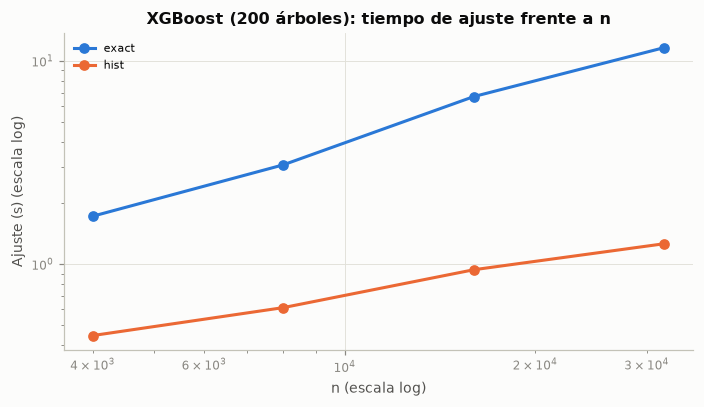

,Exponente empírico
Método,
exact,"0,94"
hist,"0,51"


**Interpretación.** Con 300 árboles, el método exacto tarda 18,86 s y el de histogramas 1,87 s (10,1 veces menos), con un AUC-PR de 0,4022 y 0,4022. La parada temprana usa 4 de 2000 árboles y reduce el ajuste de 16,1 s a 0,6 s, con un AUC-PR de 0,3380 frente a 0,3650.

Lo anterior indica que discretizar cada característica en a lo sumo 256 bins elimina el ordenamiento O(n log n) por nodo del método exacto, y la pérdida de exactitud es nula en la práctica porque la mayoría de las columnas son binarias o tienen pocos valores distintos. La parada temprana ahorra cómputo, pero aquí se detuvo con muy pocos árboles: el conjunto de validación (el final del entrenamiento, ya en 2009) deja de mejorar casi de inmediato porque lo aprendido con 2008 no se traslada, y en prueba pierde AUC-PR. Su efecto de regularización depende de que la validación represente el periodo de uso.

Por tal motivo, se opta por `tree_method='hist'` en todos los experimentos (como se hizo) y por no usar GPU. La máquina no tiene GPU NVIDIA y, con unos 41 000 registros, tampoco se justifica: con histogramas, el ajuste en CPU ya tarda 1,87 s, y scikit-learn está diseñado para CPU (su soporte de GPU es experimental y cubre pocos estimadores), de modo que el preprocesamiento, el balanceo y los demás modelos seguirían en CPU.

In [57]:
import shutil
xg = cp["xgboost"].copy()
gpu_txt = ("disponible" if (xgboost.build_info().get("USE_CUDA") and shutil.which("nvidia-smi")) else
           "no disponible, porque no hay GPU NVIDIA (con device='cuda', XGBoost recurre a la CPU sin error)")
xg["GPU"] = gpu_txt
tabla(xg, dec=4, indice=False)
xe = cp["xgboost_escalamiento"]
xp = cp["xgboost_parada"]
tabla(xp, dec=4, indice=False)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
grafico_escalamiento(ax, xe, "Ajuste (s)", "XGBoost (200 árboles): tiempo de ajuste frente a n")
plt.tight_layout()
plt.show()
exp_xgb = exponentes(xe)
tabla(exp_xgb.to_frame(), dec=2)

ex = xg[xg["Configuración"].str.contains("exact")].iloc[0]
hi_ = xg[xg["Configuración"].str.contains("hist")].iloc[0]
interpretar(
    f"Con 300 árboles, el método exacto tarda {num(ex['Ajuste (s)'], 2)} s y el de histogramas {num(hi_['Ajuste (s)'], 2)} s "
    f"({num(ex['Ajuste (s)'] / hi_['Ajuste (s)'], 1)} veces menos), con un AUC-PR de {num(ex['AUC-PR prueba'], 4)} y "
    f"{num(hi_['AUC-PR prueba'], 4)}. La parada temprana usa {int(xp['Árboles usados'].iloc[1])} de "
    f"{int(xp['Árboles usados'].iloc[0])} árboles y reduce el ajuste de {num(xp['Ajuste (s)'].iloc[0], 1)} s a "
    f"{num(xp['Ajuste (s)'].iloc[1], 1)} s, con un AUC-PR de {num(xp['AUC-PR prueba'].iloc[1], 4)} frente a "
    f"{num(xp['AUC-PR prueba'].iloc[0], 4)}.",
    conectar("Lo anterior indica que", "Discretizar cada característica en a lo sumo 256 bins elimina el ordenamiento "
             "O(n log n) por nodo del método exacto, y la pérdida de exactitud es nula en la práctica porque la mayoría "
             "de las columnas son binarias o tienen pocos valores distintos. " + ("La parada temprana ahorra cómputo, "
             "pero aquí se detuvo con muy pocos árboles: el conjunto de validación (el final del entrenamiento, ya en "
             "2009) deja de mejorar casi de inmediato porque lo aprendido con 2008 no se traslada, y en prueba pierde "
             "AUC-PR. Su efecto de regularización depende de que la validación represente el periodo de uso."
             if xp["AUC-PR prueba"].iloc[1] < xp["AUC-PR prueba"].iloc[0] else
             "La parada temprana ahorra cómputo y actúa como regularización, siempre que el conjunto de validación sea "
             "independiente y posterior en el tiempo.")),
    conectar("Por tal motivo, se opta por", "`tree_method='hist'` en todos los experimentos (como se hizo) y por no usar "
             "GPU. La máquina no tiene GPU NVIDIA y, con unos 41 000 registros, tampoco se justifica: con histogramas, el "
             f"ajuste en CPU ya tarda {num(hi_['Ajuste (s)'], 2)} s, y scikit-learn está diseñado para CPU (su soporte de "
             "GPU es experimental y cubre pocos estimadores), de modo que el preprocesamiento, el balanceo y los demás "
             "modelos seguirían en CPU."))

## 6.6 SVM: núcleo exacto frente a LinearSVC, SGD y aproximación de Nyström

Método,n,Ajuste (s),Inferencia (s),AUC prueba,AUC-PR prueba
SVC núcleo RBF (exacto),1 000,"0,0121","0,1150","0,6119","0,3837"
LinearSVC,1 000,"0,0036","0,0016","0,4565","0,2948"
SGD (bisagra),1 000,"0,0084","0,0007","0,5391","0,3330"
Nyström (300) + LinearSVC,1 000,"0,0795","0,1759","0,6732","0,5008"
SVC núcleo RBF (exacto),2 000,"0,0438","0,2452","0,6309","0,4012"
LinearSVC,2 000,"0,0076","0,0016","0,4528","0,2953"
SGD (bisagra),2 000,"0,0155","0,0008","0,5353","0,3350"
Nyström (300) + LinearSVC,2 000,"0,1169","0,1190","0,6739","0,5012"
SVC núcleo RBF (exacto),4 000,"0,2283","0,5992","0,5291","0,3096"
LinearSVC,4 000,"0,0209","0,0020","0,4538","0,2967"


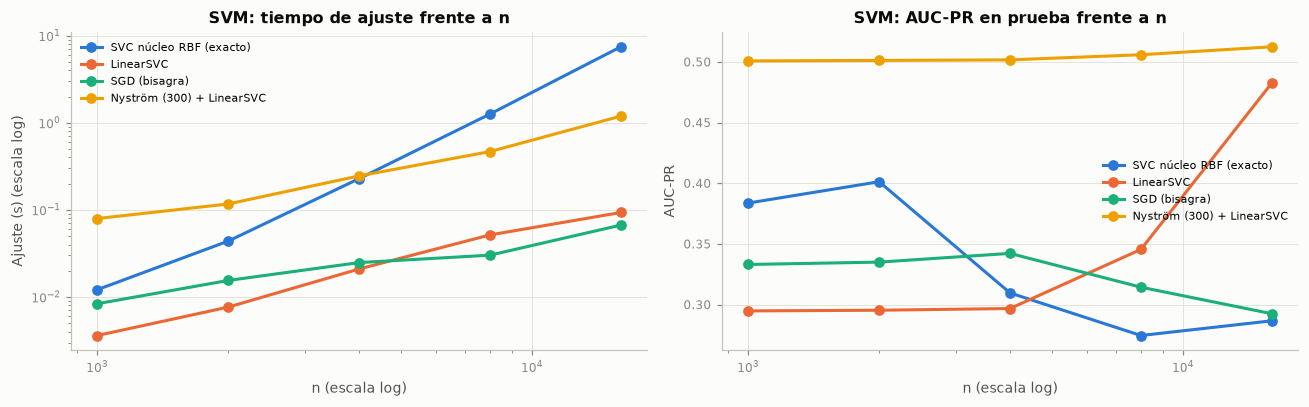

,Exponente empírico
Método,
LinearSVC,"1,21"
Nyström (300) + LinearSVC,"0,98"
SGD (bisagra),"0,70"
SVC núcleo RBF (exacto),"2,34"


**Interpretación.** El exponente empírico del SVC con núcleo exacto es 1,21, frente a 1,21 (LinearSVC), 0,98 (Nyström (300) + LinearSVC) y 0,70 (SGD (bisagra)). Con n = 16 000, el núcleo exacto tarda 7,5 s y Nyström + LinearSVC 1,19 s, con AUC-PR de 0,2866 y 0,5124.

Así mismo, el exponente del núcleo exacto queda por debajo del cuadrático teórico en este rango de n, porque SMO trabaja sobre los vectores de soporte y la caché del núcleo; aun así, su tiempo absoluto es varias veces el de la aproximación y su costo teórico crece de forma cuadrática a cúbica cuando n aumenta. Además, con gamma='scale' y C = 1 sin ajustar, el núcleo exacto discrimina peor en prueba que la aproximación de Nyström con gamma = 0,03: la elección de gamma importa más que la exactitud del núcleo. Con 20 configuraciones por pliegue en la validación anidada, el núcleo exacto multiplicaría el costo sin ventaja demostrada.

En consecuencia, se decide usar Nyström + LinearSVC como la SVM del proyecto (y Nyström + LinearSVR como la SVR), con el número de componentes y gamma como hiperparámetros, tal como recomienda la guía para problemas de gran tamaño de muestra.

In [58]:
sv = cp["svm_escalamiento"]
tabla(sv, dec=4, indice=False)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
grafico_escalamiento(axs[0], sv, "Ajuste (s)", "SVM: tiempo de ajuste frente a n")
for i, (m_, g) in enumerate(sv.groupby("Método", sort=False)):
    axs[1].semilogx(g["n"], g["AUC-PR prueba"], marker="o", color=CAT[i], label=m_)
axs[1].set(title="SVM: AUC-PR en prueba frente a n", xlabel="n (escala log)", ylabel="AUC-PR")
axs[1].legend(fontsize=7)
plt.tight_layout()
plt.show()
exp_svm = exponentes(sv)
tabla(exp_svm.to_frame(), dec=2)

nmax = sv[sv["Método"].str.startswith("SVC")]["n"].max()
s_k = sv[(sv["Método"].str.startswith("SVC")) & (sv["n"] == nmax)].iloc[0]
s_n = sv[(sv["Método"].str.startswith("Nyström")) & (sv["n"] == nmax)].iloc[0]
interpretar(
    f"El exponente empírico del SVC con núcleo exacto es {num(exp_svm.filter(like='SVC').iloc[0], 2)}, frente a "
    f"{enumerar([num(v, 2) + ' (' + k + ')' for k, v in exp_svm.items() if not k.startswith('SVC')], codigo=False)}. Con "
    f"n = {num(nmax)}, el núcleo exacto tarda {num(s_k['Ajuste (s)'], 1)} s y Nyström + LinearSVC "
    f"{num(s_n['Ajuste (s)'], 2)} s, con AUC-PR de {num(s_k['AUC-PR prueba'], 4)} y {num(s_n['AUC-PR prueba'], 4)}.",
    ("Así mismo, el crecimiento superlineal del núcleo exacto confirma el costo cuadrático a cúbico de SMO. "
     if exp_svm.filter(like="SVC").iloc[0] >= 1.8 else
     "Así mismo, el exponente del núcleo exacto queda por debajo del cuadrático teórico en este rango de n, porque "
     "SMO trabaja sobre los vectores de soporte y la caché del núcleo; aun así, su tiempo absoluto es varias veces el "
     "de la aproximación y su costo teórico crece de forma cuadrática a cúbica cuando n aumenta. ")
    + "Además, con gamma='scale' y C = 1 sin ajustar, el núcleo exacto discrimina peor en prueba que la aproximación de "
      "Nyström con gamma = 0,03: la elección de gamma importa más que la exactitud del núcleo. Con 20 configuraciones "
      "por pliegue en la validación anidada, el núcleo exacto multiplicaría el costo sin ventaja demostrada.",
    conectar("En consecuencia, se decide", "Usar Nyström + LinearSVC como la SVM del proyecto (y Nyström + LinearSVR como "
             "la SVR), con el número de componentes y gamma como hiperparámetros, tal como recomienda la guía para "
             "problemas de gran tamaño de muestra."))

## 6.7 Paralelización con `joblib`

Se mide la validación cruzada de un Random Forest (200 árboles) paralelizando entre pliegues con los *backends* `loky` (procesos) y `threading` (hilos), y paralelizando entre árboles dentro del propio bosque. La aceleración es el tiempo con un núcleo dividido por el tiempo con n_jobs núcleos; la eficiencia es la aceleración dividida por n_jobs.

Nivel,Backend,n_jobs,Tiempo (s),Aceleración,Eficiencia
entre pliegues (cross_validate),loky,1,"7,97","1,00","1,00"
entre pliegues (cross_validate),loky,2,"9,20","0,87","0,43"
entre pliegues (cross_validate),loky,4,"8,22","0,97","0,24"
entre pliegues (cross_validate),loky,8,"9,84","0,81","0,10"
entre pliegues (cross_validate),threading,1,"7,34","1,00","1,00"
entre pliegues (cross_validate),threading,2,"6,19","1,18","0,59"
entre pliegues (cross_validate),threading,4,"6,54","1,12","0,28"
entre pliegues (cross_validate),threading,8,"5,16","1,42","0,18"
entre árboles (RandomForest n_jobs),threading (interno),1,"7,69","1,00","1,00"
entre árboles (RandomForest n_jobs),threading (interno),2,"5,19","1,48","0,74"


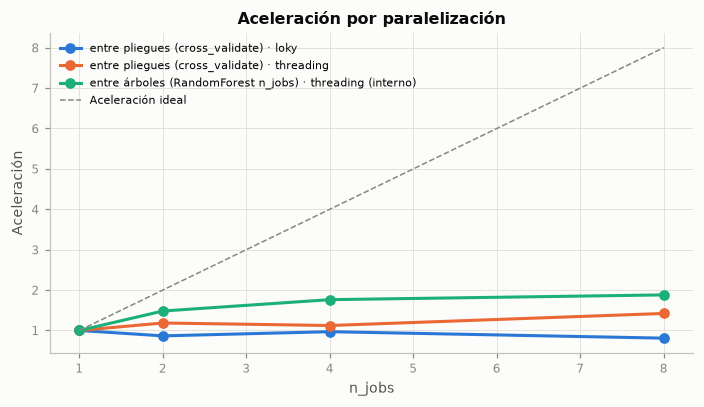

**Interpretación.** La mayor aceleración es de 1,9 veces con 8 núcleos (entre árboles (RandomForest n_jobs), threading (interno)), una eficiencia del 24 %. Con 3 pliegues internos, paralelizar entre pliegues no puede superar una aceleración de 3, porque no hay más tareas que repartir.

Es decir, la granularidad decide la escalabilidad: entre pliegues hay pocas tareas grandes y entre árboles hay muchas tareas pequeñas. Los hilos funcionan bien en scikit-learn y XGBoost porque el núcleo de cómputo libera el GIL; los procesos de `loky` pagan el arranque de cada trabajador y la copia de los datos, y con tareas de pocos segundos ese costo fijo anula la ganancia (aquí `loky` entre pliegues fue incluso más lento que un solo núcleo).

Por tal motivo, se opta por paralelizar al nivel más grueso disponible, que en este proyecto son las 825 tareas (combinación × pliegue externo): 10 procesos independientes con un hilo cada uno, sin sobresuscribir los núcleos. Herramientas distribuidas como Dask o Ray no se justifican con 41 000 registros que caben en memoria y una sola máquina; serían la opción si el número de combinaciones o el tamaño de los datos exigiera varios nodos.

In [59]:
pa = cp["paralelizacion"]
tabla(pa, dec=2, indice=False)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for i, ((niv, be), g) in enumerate(pa.groupby(["Nivel", "Backend"], sort=False)):
    ax.plot(g["n_jobs"], g["Aceleración"], marker="o", color=CAT[i], label=f"{niv} · {be}")
ax.plot(pa["n_jobs"].unique(), pa["n_jobs"].unique(), color=GRIS, ls="--", lw=1, label="Aceleración ideal")
ax.set(title="Aceleración por paralelización", xlabel="n_jobs", ylabel="Aceleración")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

mej = pa.loc[pa["Aceleración"].idxmax()]
interpretar(
    f"La mayor aceleración es de {num(mej['Aceleración'], 1)} veces con {int(mej['n_jobs'])} núcleos "
    f"({mej['Nivel']}, {mej['Backend']}), una eficiencia del {pct(mej['Eficiencia'], 0)}. Con 3 pliegues internos, "
    "paralelizar entre pliegues no puede superar una aceleración de 3, porque no hay más tareas que repartir.",
    conectar("Es decir,", "La granularidad decide la escalabilidad: entre pliegues hay pocas tareas grandes y entre árboles "
             "hay muchas tareas pequeñas. Los hilos funcionan bien en scikit-learn y XGBoost porque el núcleo de cómputo "
             "libera el GIL; los procesos de `loky` pagan el arranque de cada trabajador y la copia de los datos, y con "
             "tareas de pocos segundos ese costo fijo anula la ganancia"
             + (" (aquí `loky` entre pliegues fue incluso más lento que un solo núcleo)."
                if (pa[(pa["Backend"] == "loky") & (pa["n_jobs"] > 1)]["Aceleración"] < 1).any() else ".")),
    conectar("Por tal motivo, se opta por", "Paralelizar al nivel más grueso disponible, que en este proyecto son las 825 "
             "tareas (combinación × pliegue externo): 10 procesos independientes con un hilo cada uno, sin sobresuscribir "
             "los núcleos. Herramientas distribuidas como Dask o Ray no se justifican con 41 000 registros que caben en "
             "memoria y una sola máquina; serían la opción si el número de combinaciones o el tamaño de los datos "
             "exigiera varios nodos."))

## 6.8 Perfilamiento: dónde está el costo real

Se perfila con `cProfile` (tiempo de CPU por función) y `memory_profiler` (memoria pico) una combinación completa del bucle anidado: XGBoost con SMOTE y optimización bayesiana en el pliegue externo más grande, es decir, 20 configuraciones × 3 pliegues internos más el reajuste final.

In [60]:
pc = cp["perfil_componentes"]
tabla(pc, dec=2, indice=False)
print(f"Tiempo total perfilado: {num(perfil['total_s'], 1)} s · memoria pico: {num(perfil['memoria_pico_mb'], 0)} MB")
dom = pc.iloc[0]
interpretar(
    f"El componente dominante es \"{dom['Componente']}\", con el {num(dom['% del total'], 1)} % del tiempo; le siguen "
    f"{enumerar([f'{r.Componente} ({num(r._3, 1)} %)' for r in pc.iloc[1:3].itertuples()], codigo=False)}. La memoria "
    f"pico de la combinación es de {num(perfil['memoria_pico_mb'], 0)} MB.",
    conectar("Esto significa que", "El costo propio del optimizador (el muestreo de TPE) es despreciable frente al "
             "ajuste de los modelos. "
             + (f"El preprocesamiento sí pesa ({num(pc.set_index('Componente').loc['Preprocesamiento (ColumnTransformer)', '% del total'], 1)} %): "
                "se reajusta en cada uno de los 60 ajustes internos aunque sus parámetros apenas cambian entre "
                "configuraciones, de modo que precalcularlo por pliegue (con `memory` en el `Pipeline`) es la "
                "optimización con mejor relación costo-beneficio después del modelo. "
                if pc.set_index('Componente').loc['Preprocesamiento (ColumnTransformer)', '% del total'] > 10 else
                "El preprocesamiento también es marginal, así que optimizarlo sería una optimización prematura. ")
             + "La memoria no es una restricción en este tamaño de datos."),
    conectar("Por lo anterior, conviene", "Concentrar las mejoras en reducir el número de ajustes (multi-fidelidad, "
             "parada temprana, menos configuraciones malas gracias a métodos adaptativos) y en el método de "
             "construcción de los árboles (`hist`), que son las palancas que actúan sobre el cuello de botella real."))

Componente,Tiempo acumulado (s),% del total
Ajuste de XGBoost (booster),"116,81","69,04"
Preprocesamiento (ColumnTransformer),"32,50","19,21"
Cálculo de la métrica (scorer),"6,42","3,80"
Predicción de XGBoost,"1,82","1,07"
SMOTE (fit_resample),"1,72","1,01"
Muestreo TPE de Optuna,"0,00","0,00"


Tiempo total perfilado: 169,2 s · memoria pico: 495 MB


**Interpretación.** El componente dominante es "Ajuste de XGBoost (booster)", con el 69,0 % del tiempo; le siguen Preprocesamiento (ColumnTransformer) (19,2 %) y Cálculo de la métrica (scorer) (3,8 %). La memoria pico de la combinación es de 495 MB.

Esto significa que el costo propio del optimizador (el muestreo de TPE) es despreciable frente al ajuste de los modelos. El preprocesamiento sí pesa (19,2 %): se reajusta en cada uno de los 60 ajustes internos aunque sus parámetros apenas cambian entre configuraciones, de modo que precalcularlo por pliegue (con `memory` en el `Pipeline`) es la optimización con mejor relación costo-beneficio después del modelo. La memoria no es una restricción en este tamaño de datos.

Por lo anterior, conviene concentrar las mejoras en reducir el número de ajustes (multi-fidelidad, parada temprana, menos configuraciones malas gracias a métodos adaptativos) y en el método de construcción de los árboles (`hist`), que son las palancas que actúan sobre el cuello de botella real.

## 6.9 Tabla comparativa: modelo estándar frente a optimizado

La tabla que pide la guía resume, para cada par, la complejidad teórica, el tiempo de ajuste, el tiempo de inferencia sobre la prueba, la memoria pico del ajuste (`tracemalloc`) y la variación del desempeño predictivo (AUC-PR o RMSE en prueba).

In [61]:
co = cp["comparativa"]
tabla(co, dec=4, indice=False)
pares_c = co.groupby("Modelo", sort=False)
ahorro = pares_c.apply(lambda g: g["Ajuste (s)"].iloc[0] / g["Ajuste (s)"].iloc[1], include_groups=False)
ahorro_i = pares_c.apply(lambda g: g["Inferencia (s)"].iloc[0] / g["Inferencia (s)"].iloc[1], include_groups=False)
dif_m = pares_c["Variación de la métrica"].last()
def veces(v, fem=False):
    if 0.9 <= v <= 1.1:
        return "similar"
    a = "a" if fem else "o"
    return f"{num(v, 1)} veces más rápid{a}" if v > 1 else f"{num(1 / v, 0)} veces más lent{a}"

interpretar(
    "Frente a la versión estándar, el ajuste de la versión optimizada es "
    + enumerar([f"{veces(v)} ({k})" for k, v in ahorro.items()], codigo=False)
    + "; la inferencia es " + enumerar([f"{veces(v, fem=True)} ({k})" for k, v in ahorro_i.items()], codigo=False)
    + ". La métrica cambia en " + enumerar([f"{num(v, 4)} ({k})" for k, v in dif_m.items()], codigo=False) + ".",
    conectar("En síntesis,", "Cada optimización actúa sobre una fase distinta: los histogramas abaratan el ajuste de XGBoost "
             "sin perder desempeño; FAISS HNSW encarece la construcción del índice pero abarata cada consulta, con una "
             "pérdida pequeña de AUC-PR; Nyström abarata la SVM y, con un gamma adecuado, incluso mejora la métrica. "
             "SAGA, que solo mejora la complejidad asintótica, es mucho más lento que Cholesky con 49 columnas."),
    conectar("Así las cosas, se decide", "Mantener en el pipeline las versiones optimizadas que ganan en tiempo sin perder "
             "desempeño y documentar las que no aplican a este tamaño de problema, en lugar de adoptarlas por defecto."))

Modelo,Versión,Complejidad teórica,Ajuste (s),Inferencia (s),Memoria pico del ajuste (MB),Métrica,Valor,Variación de la métrica
KNN (k = 40),Estándar: búsqueda exhaustiva,O(n · p) por consulta,"0,0013","3,2630","0,0030",AUC-PR,"0,5060","0,0000"
KNN (k = 40),Optimizado: FAISS HNSW (aproximado),≈ O(log n) por consulta,"1,9673","0,2409","0,0008",AUC-PR,"0,4850","-0,0210"
Ridge,Estándar: Cholesky,O(n · p² + p³),"0,0136","0,0006","6,3180",RMSE,"1,0972","0,0000"
Ridge,Optimizado: SAGA,O(n · p) por época,"11,7080","0,0007","6,9234",RMSE,"1,0866","-0,0106"
XGBoost (300 árboles),Estándar: tree_method='exact',O(B · p · n log n),"17,0442","0,0504","0,2567",AUC-PR,"0,4022","0,0000"
XGBoost (300 árboles),Optimizado: tree_method='hist',O(B · p · n),"1,7343","0,0506","0,2567",AUC-PR,"0,4022","-0,0000"
SVM RBF (n = 8000),Estándar: SVC núcleo exacto,O(n²) a O(n³),"1,2283","1,2241","6,0471",AUC-PR,"0,2745","0,0000"
SVM RBF (n = 8000),Optimizado: Nyström (300) + LinearSVC,O(n · m · p + m³),"0,4655","0,1342","28,1950",AUC-PR,"0,5059","0,2314"


**Interpretación.** Frente a la versión estándar, el ajuste de la versión optimizada es 1 555 veces más lento (KNN (k = 40)), 862 veces más lento (Ridge), 9,8 veces más rápido (XGBoost (300 árboles)) y 2,6 veces más rápido (SVM RBF (n = 8000)); la inferencia es 13,5 veces más rápida (KNN (k = 40)), 1 veces más lenta (Ridge), similar (XGBoost (300 árboles)) y 9,1 veces más rápida (SVM RBF (n = 8000)). La métrica cambia en -0,0210 (KNN (k = 40)), -0,0106 (Ridge), -0,0000 (XGBoost (300 árboles)) y 0,2314 (SVM RBF (n = 8000)).

En síntesis, cada optimización actúa sobre una fase distinta: los histogramas abaratan el ajuste de XGBoost sin perder desempeño; FAISS HNSW encarece la construcción del índice pero abarata cada consulta, con una pérdida pequeña de AUC-PR; Nyström abarata la SVM y, con un gamma adecuado, incluso mejora la métrica. SAGA, que solo mejora la complejidad asintótica, es mucho más lento que Cholesky con 49 columnas.

Así las cosas, se decide mantener en el pipeline las versiones optimizadas que ganan en tiempo sin perder desempeño y documentar las que no aplican a este tamaño de problema, en lugar de adoptarlas por defecto.